# Texty, dokumenty, PDF a OCR – praktická ukázka

**Předmět:** Nástroje datové analýzy a prezentace dat

Praktická část zápočtového projektu. Notebook lze spustit v **Google Colabu** nebo lokálně.
Podrobný postup a přehled všech podkladů jsou v souboru `README.md` v kořeni repozitáře.

**Google Colab:**
1. Spusťte instalační buňku (může trvat několik minut).
2. Po výzvě nahrajte soubor `data/cvicne_dokumenty.zip` z repozitáře.
3. Spouštějte následující buňky shora dolů (`Shift+Enter`).

**Lokálně:** Notebook najde soubory automaticky ve složce `data/cvicne_dokumenty`.
První instalační buňku přeskočte a nainstalujte závislosti podle README.

| Část | Co ukazuje |
|---|---|
| 1 | Textové soubory a kódování češtiny |
| 2 | Word (.docx) – odstavce, styly, tabulky |
| 3 | Digitální PDF – text a tabulky do pandas |
| 4 | Jak poznat, jestli PDF potřebuje OCR |
| 5 | OCR obrázku (Tesseract) a jistota rozpoznání |
| 6 | Měření kvality OCR (CER, WER) |
| 7 | Předzpracování špatného skenu |


## 0. Instalace a příprava cvičných dokumentů

In [ ]:
# Tato instalační buňka je určena pro Google Colab.
# Při lokálním spuštění ji přeskočte (postup v README.md).
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ces ocrmypdf > /dev/null
!pip -q install pymupdf pdfplumber pytesseract python-docx rapidfuzz chardet opencv-python-headless


In [ ]:
from pathlib import Path
import io
import zipfile

# Při lokálním spuštění najdeme dokumenty automaticky v repozitáři.
kandidati = [
    Path("data/cvicne_dokumenty"),         # notebook spuštěný z kořene repozitáře
    Path("../data/cvicne_dokumenty"),      # notebook spuštěný ze složky notebooks
    Path("cvicne_dokumenty"),              # Google Colab po rozbalení ZIPu
]
D = next((p for p in kandidati if (p / "01_zapis_z_porady.pdf").is_file()), None)

if D is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Cvičné dokumenty nenalezeny. Otevřete notebook v kořeni repozitáře "
            "nebo rozbalte data/cvicne_dokumenty.zip do pracovního adresáře."
        ) from exc

    print("Nahrajte soubor data/cvicne_dokumenty.zip z repozitáře.")
    nahrane = files.upload()
    for nazev, obsah in nahrane.items():
        if nazev.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(obsah)) as archiv:
                # Kontrola cest v archivu před rozbalením.
                for polozka in archiv.namelist():
                    cesta = Path(polozka)
                    if cesta.is_absolute() or ".." in cesta.parts:
                        raise ValueError(f"Nepovolená cesta v ZIPu: {polozka}")
                archiv.extractall(".")
    D = next((p for p in kandidati if (p / "01_zapis_z_porady.pdf").is_file()), None)

if D is None:
    raise FileNotFoundError("Cvičná data nebyla nalezena. Nahrajte cvicne_dokumenty.zip.")

print("Cvičné dokumenty:", D.resolve())
sorted(p.name for p in D.glob("0*"))


## 1. Textové soubory a kódování

Stejný text uložený ve třech kódováních. Nejčastější problém s českými daty: soubor z Windows (`cp1250`)
otevřený jako UTF-8 nebo naopak.

In [ ]:
import chardet

def dekoduj(raw, kodovani):                  # errors="replace": nevalidní bajty -> �, nespadne to
    return raw.decode(kodovani, errors="replace").splitlines()[0]

for f in sorted(D.glob("07_kodovani_*.txt")):
    raw = f.read_bytes()
    odhad = chardet.detect(raw)
    print("=" * 70)
    print(f.name, "| odhad chardet:", odhad["encoding"], f"(jistota {odhad['confidence']:.0%})")
    for k in ["utf-8", "latin-1", "cp1250", "iso8859-2"]:
        print(f"  jako {k:<10}:", dekoduj(raw, k))

07_kodovani_cp1250.txt | odhad chardet: Windows-1254 (jistota 42%)
  jako utf-8     : P��li� �lu�ou�k� k�� �p�l ��belsk� �dy.
  jako latin-1   : Pøíli luouèký kùò úpìl ïábelské ódy.
  jako cp1250    : Příliš žluťoučký kůň úpěl ďábelské ódy.
  jako iso8859-2 : Příli luoučký kůň úpěl ďábelské ódy.
07_kodovani_iso8859-2.txt | odhad chardet: ISO-8859-9 (jistota 42%)
  jako utf-8     : P��li� �lu�ou�k� k�� �p�l ��belsk� �dy.
  jako latin-1   : Pøíli¹ ¾lu»ouèký kùò úpìl ïábelské ódy.
  jako cp1250    : Přílią ľlu»oučký kůň úpěl ďábelské ódy.
  jako iso8859-2 : Příliš žluťoučký kůň úpěl ďábelské ódy.
07_kodovani_utf8.txt | odhad chardet: utf-8 (jistota 99%)
  jako utf-8     : Příliš žluťoučký kůň úpěl ďábelské ódy.
  jako latin-1   : PÅÃ­liÅ¡ Å¾luÅ¥ouÄkÃ½ kÅ¯Å ÃºpÄl ÄÃ¡belskÃ© Ã³dy.
  jako cp1250    : PĹ™Ă­liĹˇ ĹľluĹĄouÄŤkĂ˝ kĹŻĹ� ĂşpÄ›l ÄŹĂˇbelskĂ© Ăłdy.
  jako iso8859-2 : PĹĂ­liĹĄ ĹžluĹĽouÄkĂ˝ kĹŻĹ ĂşpÄl ÄĂĄbelskĂŠ Ăłdy.


**Poznámka:** `cp1250` a `iso8859-2` se liší jen u některých písmen (např. š, ť, ž), proto je automatický odhad
u krátkých textů nespolehlivý. Dnes je správná volba **vždy UTF-8** (`encoding="utf-8"`, v Excelu `utf-8-sig`).

## 2. Word (.docx)

In [ ]:
import docx
import pandas as pd

d = docx.Document(D / "06_smlouva.docx")

for p in d.paragraphs:
    if p.text.strip():
        print(f"[{p.style.name:<10}] {p.text}")

[Title     ] Smlouva o poskytnutí služeb
[Normal    ] č. 2026/OCR/014 (cvičný fiktivní dokument)
[Heading 1 ] 1. Smluvní strany
[Heading 1 ] 2. Předmět smlouvy
[Normal    ] Poskytovatel se zavazuje pro objednatele zajistit digitalizaci archivních dokumentů, rozpoznání textu (OCR) a export výsledků do prohledávatelného formátu PDF/A.
[Heading 2 ] 2.1 Rozsah služeb
[List Paragraph] skenování nejvýše 1 200 stran formátu A4
[List Paragraph] rozpoznání textu v českém jazyce s přesností alespoň 97 %
[List Paragraph] dodání výsledků ve formátech PDF/A a CSV
[Heading 1 ] 3. Cena a platební podmínky
[Normal    ] Celková cena za poskytnuté služby činí 45 600,00 Kč bez DPH. K ceně bude připočtena DPH ve výši 21 %. Faktura je splatná do 14 dnů od data vystavení.
[Heading 1 ] 4. Závěrečná ustanovení
[Normal    ] Smlouva nabývá účinnosti dnem 1. 12. 2026. Případné spory budou řešeny přednostně dohodou. Kontaktní osoba: Jiří Řezáč, jiri.rezac@priklad.example.


In [ ]:
# Tabulka z Wordu rovnou do pandas
t = d.tables[0]
hlavicka = [c.text for c in t.rows[0].cells]
df_strany = pd.DataFrame([[c.text for c in r.cells] for r in t.rows[1:]], columns=hlavicka)
df_strany

,Strana,Údaje
0,Poskytovatel,"Fiktivní Data s.r.o., Vzorová 12, 400 01 Ústí ..."
1,Objednatel,"Příkladová univerzita, Cvičná 5, 110 00 Praha ..."


## 3. Digitální PDF – text a tabulky

Digitální PDF (vytvořené ze Wordu, účetního systému…) **má textovou vrstvu**, takže OCR není potřeba.

In [ ]:
import pymupdf, pdfplumber

with pymupdf.open(D / "01_zapis_z_porady.pdf") as pdf:
    print("Počet stran:", len(pdf), "| metadata:", pdf.metadata["title"])
    print(pdf[0].get_text()[:600])

Počet stran: 1 | metadata: Zápis z porady projektového týmu
Zápis z porady projektového týmu
Projekt Digitalizace archivu
Datum: 14. října 2026
Místo: zasedací místnost B2
Přítomni: Jana Nováková, Petr Svoboda, Lucie Horáková, Martin Dvořák
Zapsala: Lucie Horáková
1. Stav digitalizace archivu
Do konce září bylo naskenováno 4 820 stran z celkových 12 500, což odpovídá 38,6 %
plánovaného rozsahu. Kvalita skenů je vyhovující, u přibližně 3 % stran je nutné
skenování opakovat kvůli šikmému zarovnání nebo stínům od vazby.
2. Rozpoznávání textu (OCR)
Pilotní test na vzorku 200 stran ukázal průměrnou přesnost rozpoznání 97,4 % na
úrovni znaků. Nejčastější chy


In [ ]:
# Tabulka z faktury -> pandas
with pdfplumber.open(D / "02_faktura_tabulka.pdf") as pdf:
    tabulka = pdf.pages[0].extract_tables()[0]

faktura = pd.DataFrame(tabulka[1:], columns=tabulka[0])

def cz_cislo(s):                       # "16 000,00" -> 16000.0
    return float(s.replace(" ", "").replace("\xa0", "").replace(",", "."))

for sl in ["Množství", "Cena/jedn. (Kč)", "Celkem (Kč)"]:
    faktura[sl] = faktura[sl].map(cz_cislo)

faktura

,Položka,Množství,Jedn.,Cena/jedn. (Kč),Celkem (Kč)
0,Licence analytického softwaru (roční),5.0,ks,3200.0,16000.0
1,Školení OCR a zpracování dokumentů,2.0,den,8500.0,17000.0
2,Konzultace,6.0,hod,1200.0,7200.0
3,Skenování archivních dokumentů,1200.0,str,4.5,5400.0


In [ ]:
# Kontrola dat: sedí součty?
print("Součet položek:", faktura["Celkem (Kč)"].sum())
print("Množství × cena = celkem:", (faktura["Množství"] * faktura["Cena/jedn. (Kč)"] == faktura["Celkem (Kč)"]).all())

# Částka z textu faktury pomocí regulárního výrazu
import re
text = pymupdf.open(D / "02_faktura_tabulka.pdf")[0].get_text()
m = re.search(r"Celkem k úhradě:\s*([\d ]+,\d{2})", text.replace("\n", " "))
print("Celkem k úhradě z textu:", cz_cislo(m.group(1)) if m else "nenalezeno")

Součet položek: 45600.0
Množství × cena = celkem: True
Celkem k úhradě z textu: 55176.0


## 4. Má PDF textovou vrstvu, nebo je to jen obrázek?

Skenované PDF je obrázek – `get_text()` vrátí prázdný řetězec. Tohle je první věc, kterou je dobré zjistit
před každým zpracováním dávky dokumentů.

In [ ]:
def zjisti_pdf(cesta):
    radky = []
    with pymupdf.open(cesta) as pdf:
        for i, strana in enumerate(pdf, 1):
            znaku = len(strana.get_text().strip())
            obrazku = len(strana.get_images())
            typ = "digitální (text)" if znaku > 20 else ("SKEN – potřeba OCR" if obrazku else "prázdná")
            radky.append({"soubor": Path(cesta).name, "strana": i, "znaků": znaku, "obrázků": obrazku, "typ": typ})
    return radky

soubory = ["01_zapis_z_porady.pdf", "02_faktura_tabulka.pdf", "03_sken_obycejny.pdf", "05_smisene.pdf"]
pd.DataFrame([r for s in soubory for r in zjisti_pdf(D / s)])

,soubor,strana,znaků,obrázků,typ
0,01_zapis_z_porady.pdf,1,1133,0,digitální (text)
1,02_faktura_tabulka.pdf,1,699,0,digitální (text)
2,03_sken_obycejny.pdf,1,0,1,SKEN – potřeba OCR
3,05_smisene.pdf,1,699,0,digitální (text)
4,05_smisene.pdf,2,0,1,SKEN – potřeba OCR


## 5. OCR obrázku (Tesseract)

Důležité je **zvolit jazyk** – `lang="ces"`. Bez něj Tesseract nezná češtinu a háčky a čárky se ztratí.

In [ ]:
import pytesseract
from PIL import Image

sken = Image.open(D / "03_sken_obycejny.png")
text_ces = pytesseract.image_to_string(sken, lang="ces")
print(text_ces)

Zápis z porady projektového týmu

Projekt Digitalizace archivu

Datum: 14. října 2026

Místo: zasedací místnost B2

Přítomni: Jana Nováková, Petr Svoboda, Lucie Horáková, Martin Dvořák
Zapsala: Lucie Horáková

1. Stav digitalizace archivu

Do konce září bylo naskenováno 4 820 stran z celkových 12 500, což odpovídá 38,6 %
plánovaného rozsahu. Kvalita skenů je vyhovující, u přibližně 3 % stran je nutné
skenování opakovat kvůli šikmému zarovnání nebo stínům od vazby.

2. Rozpoznávání textu (OCR)

Pilotní test na vzorku 200 stran ukázal průměrnou přesnost rozpoznání 97,4 % na
úrovni znaků. Nejčastější chyby vznikají u slov s háčky a čárkami, u číslic a u textu
menšího než 9 bodů. Tým se dohodl, že všechny skeny budou před rozpoznáním
narovnány a převedeny do černobílého obrazu.

Mu

3. Úkoly do příští porady
1. Petr Svoboda - připravit předzpracování skenů (narovnání, ořez) do 30. 10. 2026.

2. Lucie Horáková - ověřit export do formátu PDF/A do 6. 11. 2026.
3. Jana Nováková - schválit rozp

In [ ]:
# Totéž se špatným jazykovým modelem (angličtina)
print(pytesseract.image_to_string(sken, lang="eng")[:400])

Zapis z porady projektového tymu

Projekt Digitalizace archivu

Datum: 14. fijna 2026

Misto: zasedaci mistnost B2

Pritomni: Jana Novakova, Petr Svoboda, Lucie Horakova, Martin Dvorak
Zapsala: Lucie Horakova

1. Stav digitalizace archivu

Do konce zafi bylo naskenovano 4 820 stran z celkovych 12 500, coz odpovida 38,6 %
planovaného rozsahu. Kvalita skend je vyhovujici, u priblizné 3 % stran je nu


In [ ]:
# Jistota rozpoznání po slovech (image_to_data) -> DataFrame
slova = pytesseract.image_to_data(sken, lang="ces", output_type=pytesseract.Output.DATAFRAME)
slova = slova[(slova.conf >= 0) & slova.text.notna()].copy()
slova["text"] = slova.text.astype(str)

print(f"Rozpoznáno slov: {len(slova)} | průměrná jistota: {slova.conf.mean():.1f} %")
slova.sort_values("conf").head(8)[["text", "conf", "left", "top", "width", "height"]]

Rozpoznáno slov: 181 | průměrná jistota: 95.0 %


,text,conf,left,top,width,height
157,Mu,14.206924,450,1044,40,7
227,lucie.horakova©priklad.example.,55.616116,195,1339,482,31
114,%,83.964905,1308,834,25,22
113,"97,4",83.964905,1234,835,62,25
78,3,89.168587,1086,665,14,22
79,%,89.168587,1113,664,25,23
87,šikmému,90.244392,567,712,129,25
172,předzpracování,90.744896,590,1097,223,32


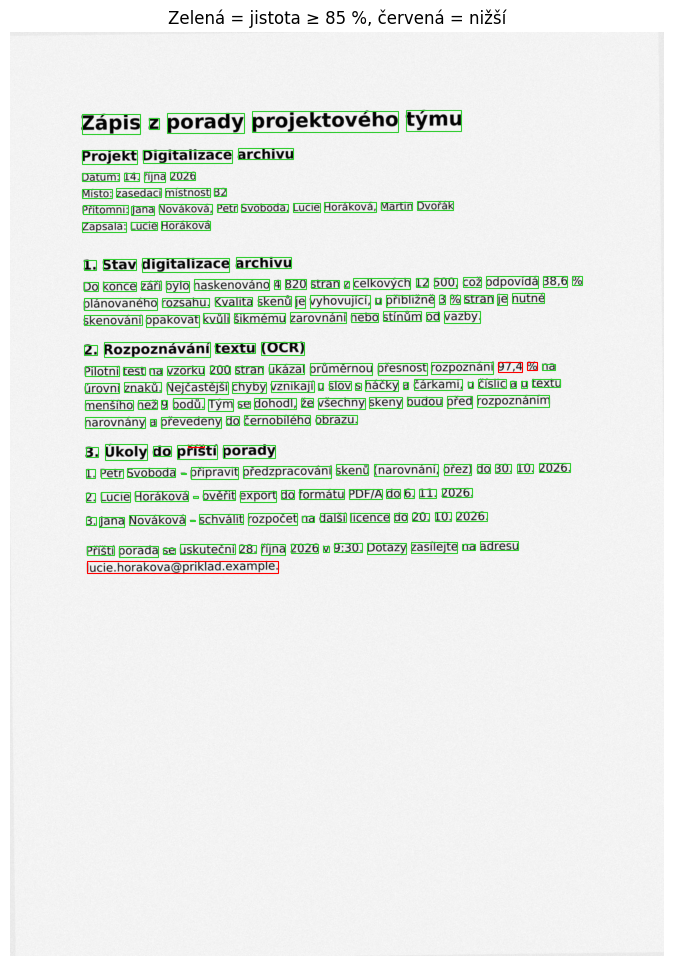

In [ ]:
# Vizualizace: slova s nízkou jistotou červeně
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(9, 12))
ax.imshow(sken, cmap="gray")
for _, r in slova.iterrows():
    barva = "red" if r.conf < 85 else "limegreen"
    ax.add_patch(patches.Rectangle((r.left, r.top), r.width, r.height, fill=False, edgecolor=barva, linewidth=0.8))
ax.set_title("Zelená = jistota ≥ 85 %, červená = nižší"); ax.axis("off")
plt.show()

## 6. Jak změřit kvalitu OCR – CER a WER

Máme **referenční text** (ground truth), takže můžeme spočítat:

* **CER** (Character Error Rate) – kolik % znaků je špatně (Levenshteinova vzdálenost / délka reference)
* **WER** (Word Error Rate) – totéž po slovech

In [ ]:
from rapidfuzz.distance import Levenshtein as L

norm = lambda s: re.sub(r"\s+", " ", s).strip()
reference = norm((D / "01_zapis_z_porady_REFERENCNI_TEXT.txt").read_text(encoding="utf-8"))

def cer(hyp): return 100 * L.distance(reference, norm(hyp)) / len(reference)
def wer(hyp):
    r, h = reference.split(), norm(hyp).split()
    return 100 * L.distance(r, h) / len(r)

print(f"Obyčejný sken, lang=ces: CER {cer(text_ces):.2f} %  | WER {wer(text_ces):.2f} %")
text_eng = pytesseract.image_to_string(sken, lang="eng")
print(f"Obyčejný sken, lang=eng: CER {cer(text_eng):.2f} %  | WER {wer(text_eng):.2f} %")

Obyčejný sken, lang=ces: CER 0.62 %  | WER 2.78 %
Obyčejný sken, lang=eng: CER 10.50 %  | WER 39.44 %


## 7. Špatný sken a předzpracování

Soubor `04_sken_spatny.png` je nakřivo, má stín od vazby, šum a nižší rozlišení – jako sken z mobilu nebo
staré kopírky. Postupně přidáme: **narovnání → zvětšení + vyhlazení → adaptivní prahování**.

In [ ]:
import numpy as np, cv2

def otoc(img, uhel):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), uhel, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

def odhad_naklonu(sedy, rozsah=np.arange(-6, 6.01, 0.25)):
    # Správný úhel = takový, při kterém jsou řádky textu nejostřejší (největší rozptyl součtů po řádcích)
    mala = cv2.resize(sedy, None, fx=0.5, fy=0.5)
    bw = (cv2.threshold(mala, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1] > 0).astype(np.float32)
    return max(rozsah, key=lambda a: np.var(otoc(bw, a).sum(axis=1)))

def binarizace(sedy):
    zvetseny = cv2.resize(sedy, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    vyhlazeny = cv2.medianBlur(zvetseny, 5)
    return cv2.adaptiveThreshold(vyhlazeny, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 41, 15)

sedy = cv2.imread(str(D / "04_sken_spatny.png"), cv2.IMREAD_GRAYSCALE)
uhel = odhad_naklonu(sedy)
narovnany = otoc(sedy, uhel)
vycisteny = binarizace(narovnany)
print(f"Odhadnutý náklon: {uhel:.2f}°")

Odhadnutý náklon: 3.25°


In [ ]:
vysledky = pd.DataFrame({
    "krok": ["1) původní sken", "2) + narovnání", "3) + zvětšení, vyhlazení, prahování"],
    "CER [%]": [cer(pytesseract.image_to_string(x, lang="ces")) for x in (sedy, narovnany, vycisteny)],
}).round(1)
vysledky

,krok,CER [%]
0,1) původní sken,56.9
1,2) + narovnání,43.2
2,"3) + zvětšení, vyhlazení, prahování",0.4


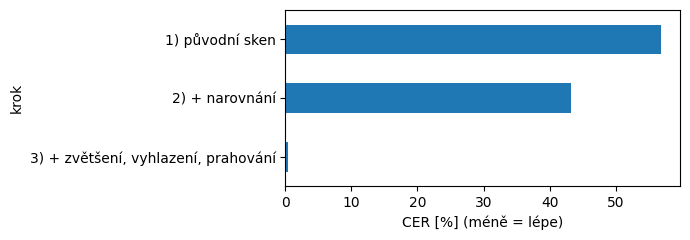

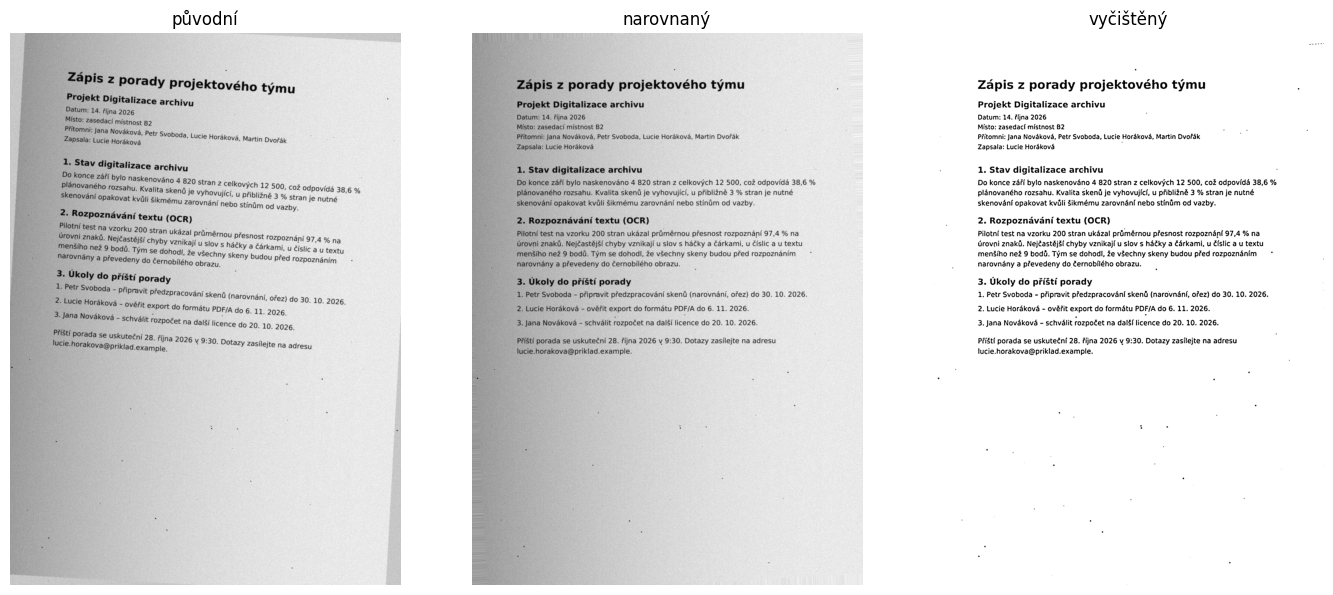

In [ ]:
vysledky.plot.barh(x="krok", y="CER [%]", legend=False, figsize=(7, 2.5), color="tab:blue")
plt.gca().invert_yaxis(); plt.xlabel("CER [%] (méně = lépe)"); plt.tight_layout(); plt.show()

fig, osy = plt.subplots(1, 3, figsize=(14, 6))
for o, im, n in zip(osy, (sedy, narovnany, vycisteny), ("původní", "narovnaný", "vyčištěný")):
    o.imshow(im, cmap="gray"); o.set_title(n); o.axis("off")
plt.tight_layout(); plt.show()